# Balls

#TODO:

      1-  How to remove side holes for angled images???
      
      2- Divide processing for different views and clean code/make functions

      1.3-sometimes two circles are overlapping one smaller and one bigger try to detect this in post processing maybe?

      2- To mask some tables the blue ball gets eaten.

      4- small dot forces min radius increase, remove it if possible from top images only or have different parameters for top/side/angle

      5- Get color values from histogram distribution inside circle/bouding box.

      6 - Test with table angle to the other side (not in development set)


In [3]:
from pathlib import Path
import sys

import cv2
import itertools
import math

import matplotlib.pyplot as plt
import numpy as np

# Make `vc-proj/` importable when running from `vc-proj/notebooks/`
cwd = Path.cwd().resolve()
project_root = cwd if (cwd / "src").exists() else cwd.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.main import (
    get_lines,
    get_inner_outer_lines,
    get_intersections,
    got_angle,
    order_points_by_angle,
)

In [4]:
DATA_DIR = Path("./../data")
IMAGE_PATH = DATA_DIR / "development_set/7a_png.rf.7cf9f36a358969bd16be866d1570a303.jpg"


IMAGE_PATH = DATA_DIR / "development_set/25f_png.rf.e20424d4f5cc6ff760cbfa7767c3ec32.jpg"

#IMAGE_PATH = DATA_DIR / "development_set/12t_png.rf.80855510c9a4d8a3a88e103ed8baeeb7.jpg"

IMAGE_PATH = DATA_DIR / "development_set/4a_png.rf.a6bb5c5706fd8628eb53d34a122cf441.jpg"
#IMAGE_PATH = DATA_DIR / "development_set/19a_png.rf.dd2935e517f1adfcd0a735f3f937fa02.jpg"



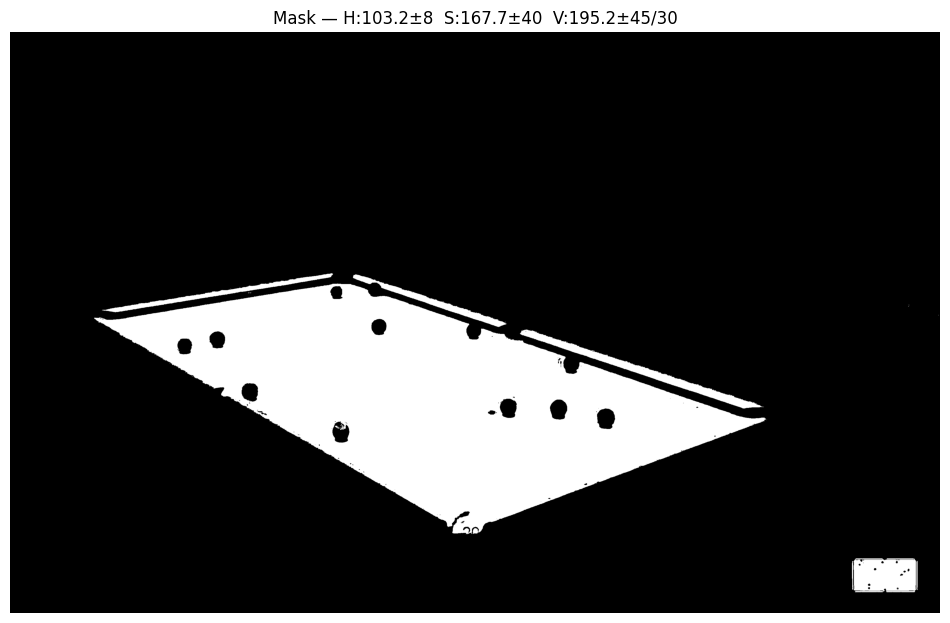

In [5]:
h_med = 103.2
s_med = 167.7   
v_med = 195.2

# Shadows values sampled
shadow_h = 106.1
shadow_s = 202.8
shadow_v = 97.4

# Light Shadow Filter
# H: 103–105 | S: 155–183 | V: 100–130       

#  Dark Shadow Filter
# H: 106 | S: 195–216 | V: 85–110
#----------------------

# Define tolerance around the median values
h_tol = 8
s_tol = 40
v_tol_up = 45      

v_tol_down = 30

lower_blue = np.array([h_med - h_tol, s_med - s_tol, v_med - v_tol_down])
upper_blue = np.array([h_med + h_tol, s_med + s_tol, v_med + v_tol_up])

# Clip to valid HSV ranges
lower_blue = np.clip(lower_blue, [0, 0, 0], [179, 255, 255])
upper_blue = np.clip(upper_blue, [0, 0, 0], [179, 255, 255])

image = cv2.imread(str(IMAGE_PATH))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
mask_table = cv2.inRange(hsv_image, lower_blue, upper_blue)

plt.figure(figsize=(12, 8))
plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title(f'Mask — H:{h_med}±{h_tol}  S:{s_med}±{s_tol}  V:{v_med}±{v_tol_up}/{v_tol_down}')
plt.show()

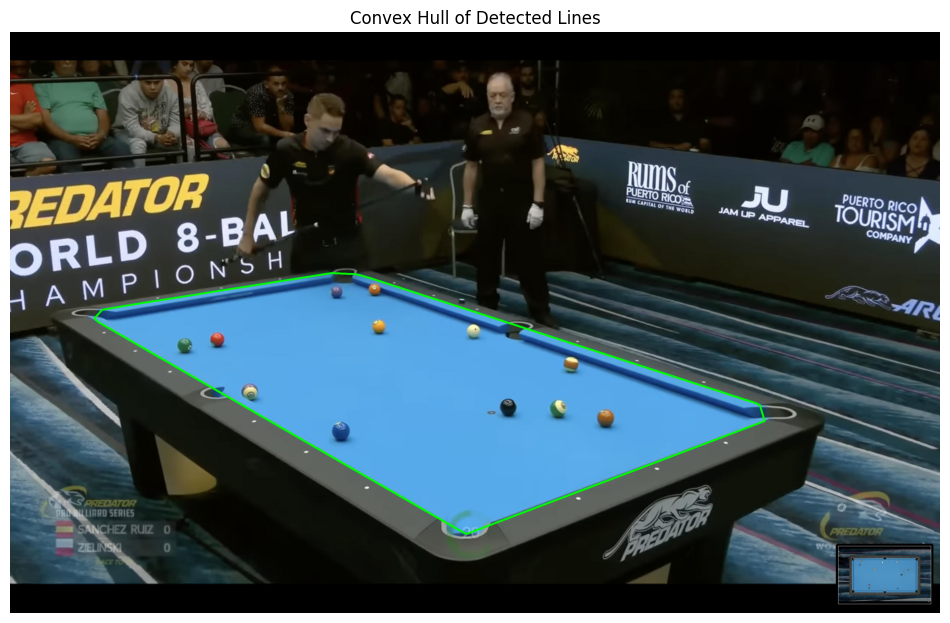

In [6]:
edges = cv2.Canny(mask_table, 50, 150)

lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold=80,
    minLineLength=100,
    maxLineGap=80
)

tmp_lines = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    if length >= 250:
        tmp_lines.append(line)
lines = tmp_lines

pts = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    pts.append((x1, y1))
    pts.append((x2, y2))

pts = np.array(pts)
hull = cv2.convexHull(pts)

line_image = image.copy()
cv2.polylines(line_image, [hull], isClosed=True, color=(0, 255, 0), thickness=5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Convex Hull of Detected Lines')
plt.show()

In [7]:

lines = get_lines(mask_table, min_length=250)

edge_points = [line[0] for line in lines]
center = [((x1 + x2) // 2, (y1 + y2) // 2) for (x1, y1, x2, y2) in edge_points]
center = np.mean(center, axis=0).astype(int)

inner_lines, outer_lines = get_inner_outer_lines(lines, center)

intersection_points_outer = get_intersections(outer_lines, image.shape[0], image.shape[1])
intersection_points_inner = get_intersections(inner_lines, image.shape[0], image.shape[1])

pts_ordered_outer, pts_ordered_inner, angles, order = order_points_by_angle(intersection_points_outer, intersection_points_inner)

is_top, is_front, is_angle, _ = got_angle(pts_ordered_outer)

print(f"Is top view: {is_top}, Is front view: {is_front}, Is angle view: {is_angle}")
for i, pt in enumerate(pts_ordered_outer):
    print(f"Outer Point {i}: {pt}, Angle: {angles[i]:.2f} degrees")

Is top view: False, Is front view: False, Is angle view: True
Outer Point 0: [ 260.8012 1015.5315], Angle: -2.14 degrees
Outer Point 1: [1218.7773  863.8519], Angle: 0.08 degrees
Outer Point 2: [2789.4795 1373.3208], Angle: -2.94 degrees
Outer Point 3: [1640.8917 1812.212 ], Angle: 1.28 degrees


In [8]:
def make_line(p1, p2):
    p1 = np.array(p1, dtype=np.float32)
    p2 = np.array(p2, dtype=np.float32)

    A = p1[1] - p2[1]
    B = p2[0] - p1[0]
    C = p1[0]*p2[1] - p2[0]*p1[1]

    return A, B, C

In [9]:
def is_above_line(pt, line):
    x, y = pt
    A, B, C = line
    y_line = -(A * x + C) / B
    return y < y_line

In [10]:
tl_inner=pts_ordered_inner[0]
tr_inner=pts_ordered_inner[1]
br_inner=pts_ordered_inner[2]
bl_inner=pts_ordered_inner[3]

tl_outer=pts_ordered_outer[0]
tr_outer=pts_ordered_outer[1]
br_outer=pts_ordered_outer[2]
bl_outer=pts_ordered_outer[3]

top_line_outer_full = make_line(tl_outer, tr_outer)
top_line_inner_full = make_line(tl_inner, tr_inner)

side_line_r_outer_full = make_line(tr_outer, br_outer)
side_line_r_inner_full = make_line(tr_inner, br_inner)

side_line_l_outer_full=make_line(tl_outer, bl_outer)
side_line_l_inner_full=make_line(tl_inner, bl_inner)

bot_line_inner_full=make_line(bl_inner, br_inner)

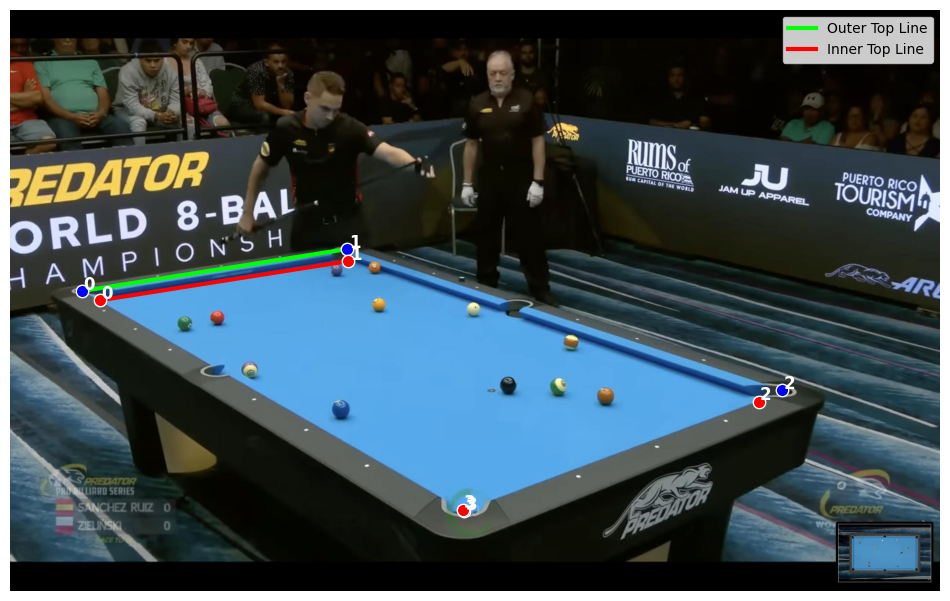

In [11]:

plt.figure(figsize=(12, 8))

# Convert HSV to RGB for Matplotlib
rgb_image = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB)
plt.imshow(rgb_image)

# Draw outer top line 
x_values = [tl_outer[0], tr_outer[0]]
y_values = [tl_outer[1], tr_outer[1]]
plt.plot(x_values, y_values, color='lime', linewidth=3, label='Outer Top Line')

# Draw inner top line (green)
x_values_inner = [tl_inner[0], tr_inner[0]]
y_values_inner = [tl_inner[1], tr_inner[1]]
plt.plot(x_values_inner, y_values_inner, color='red', linewidth=3, label='Inner Top Line')

# Optional: draw all points for reference
for i, (x, y) in enumerate(pts_ordered_outer):
    plt.scatter(x, y, color='blue', s=80, edgecolors='white', zorder=5)
    plt.text(x + 5, y - 5, str(i), color='white', fontsize=12, weight='bold', zorder=6)

for i, (x, y) in enumerate(pts_ordered_inner):
    plt.scatter(x, y, color='red', s=80, edgecolors='white', zorder=5)
    plt.text(x + 5, y - 5, str(i), color='white', fontsize=12, weight='bold', zorder=6)

plt.axis('off')
plt.legend()
plt.show()

In [12]:

cloth_color = np.array([h_med, s_med, v_med], dtype=np.float32)
threshold = 90 

height, width = hsv_image.shape[:2]

h_channel = hsv_image[:, :, 0]
s_channel = hsv_image[:, :, 1]
v_channel = hsv_image[:, :, 2]

xx, yy = np.meshgrid(np.arange(width), np.arange(height))
coords = np.stack([xx.ravel(), yy.ravel()], axis=-1)

A, B, C = top_line_inner_full
y_line = -(A * coords[:, 0] + C) / B
mask_line_flat = coords[:, 1] < y_line
mask_line = mask_line_flat.reshape(height, width)

mask_x = (xx >= tl_outer[0]) & (xx <= tr_outer[0])
top_spatial_region = mask_line & mask_x

final_side_mask = np.zeros((height, width), dtype=bool)

if is_angle and tl_outer[0] < bl_outer[0]:
    print("Table is leaning left.")
    A_out, B_out, C_out = side_line_r_outer_full
    A_in, B_in, C_in = side_line_r_inner_full

    x_line_r_outer = -(B_out * coords[:, 1] + C_out) / A_out
    x_line_r_inner = -(B_in * coords[:, 1] + C_in) / A_in
    
    mask_side_combined_flat = (coords[:, 0] > x_line_r_inner) & (coords[:, 0] < x_line_r_outer)
    final_side_mask = mask_side_combined_flat.reshape(height, width)

elif is_angle and tl_outer[0] > bl_outer[0]:
    print("Table is leaning right.")
    A_out, B_out, C_out = side_line_l_outer_full
    A_in, B_in, C_in = side_line_l_inner_full

    x_line_l_outer = -(B_out * coords[:, 1] + C_out) / A_out
    x_line_l_inner = -(B_in * coords[:, 1] + C_in) / A_in
    
    mask_side_combined_flat = (coords[:, 0] > x_line_l_outer) & (coords[:, 0] < x_line_l_inner)
    final_side_mask = mask_side_combined_flat.reshape(height, width)

all_spatial_regions = top_spatial_region | final_side_mask


is_dark_shadow = (
    (h_channel >= 95) & (h_channel <= 115) &  
    (s_channel > 184) &                        
    (v_channel < 114)                          
)

diff = np.linalg.norm(hsv_image.astype(np.float32) - cloth_color, axis=2)
mask_color_old = diff <= threshold

h_tol = 6
s_tol_up = 10
s_tol_down = 40
v_tol_up = 50
v_tol_down = 200

lower_blue = np.array([h_med - h_tol, s_med - s_tol_down, v_med - v_tol_down])
upper_blue = np.array([h_med + h_tol, s_med + s_tol_up, v_med + v_tol_up])

lower_blue = np.clip(lower_blue, [0, 0, 0], [179, 255, 255])
upper_blue = np.clip(upper_blue, [0, 0, 0], [179, 255, 255])

mask_strict_new = cv2.inRange(hsv_image, lower_blue, upper_blue) > 0

all_valid_colors = is_dark_shadow | mask_color_old | mask_strict_new

mask_final = all_spatial_regions & all_valid_colors

hsv_image_shadow_masked = hsv_image.copy()
hsv_image_shadow_masked[mask_final] = [h_med, s_med, v_med]

Table is leaning left.


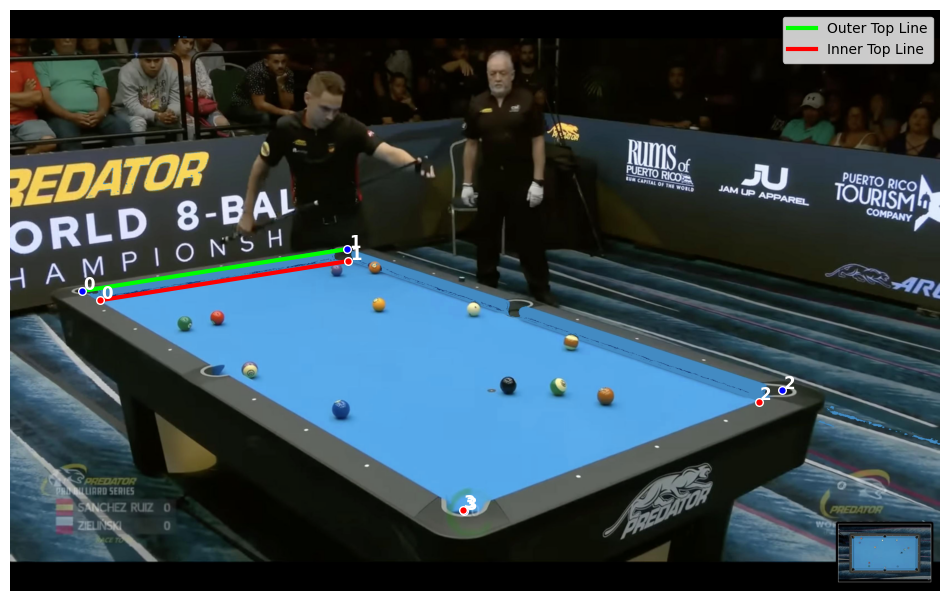

In [13]:
plt.figure(figsize=(12, 8))

# Convert HSV image (masked or original) to RGB for display
rgb_image = cv2.cvtColor(hsv_image_shadow_masked, cv2.COLOR_HSV2RGB)
plt.imshow(rgb_image)

# -----------------------------
# Draw outer top line (lime)
x_outer = [tl_outer[0], tr_outer[0]]
y_outer = [tl_outer[1], tr_outer[1]]
plt.plot(x_outer, y_outer, color='lime', linewidth=3, label='Outer Top Line')

# Draw inner top line (red)
x_inner = [tl_inner[0], tr_inner[0]]
y_inner = [tl_inner[1], tr_inner[1]]
plt.plot(x_inner, y_inner, color='red', linewidth=3, label='Inner Top Line')

# -----------------------------
# Draw outer corner points
for i, (x, y) in enumerate(pts_ordered_outer):
    plt.scatter(x, y, color='blue', s=30, edgecolors='white', zorder=5)
    plt.text(x + 5, y - 5, str(i), color='white', fontsize=12, weight='bold', zorder=6)

# Draw inner corner points
for i, (x, y) in enumerate(pts_ordered_inner):
    plt.scatter(x, y, color='red', s=30, edgecolors='white', zorder=5)
    plt.text(x + 5, y - 5, str(i), color='white', fontsize=12, weight='bold', zorder=6)

plt.axis('off')
plt.legend()
plt.show()

In [14]:
distance_tl = np.linalg.norm(tl_inner - tl_outer)
distance_tr = np.linalg.norm(tr_inner - tr_outer)
distance_br = np.linalg.norm(br_inner - br_outer)
distance_bl = np.linalg.norm(bl_inner - bl_outer)

print(f"Distance between top-left inner and outer: {distance_tl:.2f} pixels")
print(f"Distance between top-right inner and outer: {distance_tr:.2f} pixels")
print(f"Distance between bottom-right inner and outer: {distance_br:.2f} pixels")
print(f"Distance between bottom-left inner and outer: {distance_bl:.2f} pixels")

tl_hole=(tl_inner+tl_outer)/2
tr_hole=(tr_inner+tr_outer)/2
br_hole=(br_inner+br_outer)/2
bl_hole=(bl_inner+bl_outer)/2


Distance between top-left inner and outer: 72.35 pixels
Distance between top-right inner and outer: 43.70 pixels
Distance between bottom-right inner and outer: 94.79 pixels
Distance between bottom-left inner and outer: 9.37 pixels


Patch corner holes using semi-circle around mid points of inner and outer corners and above inner line

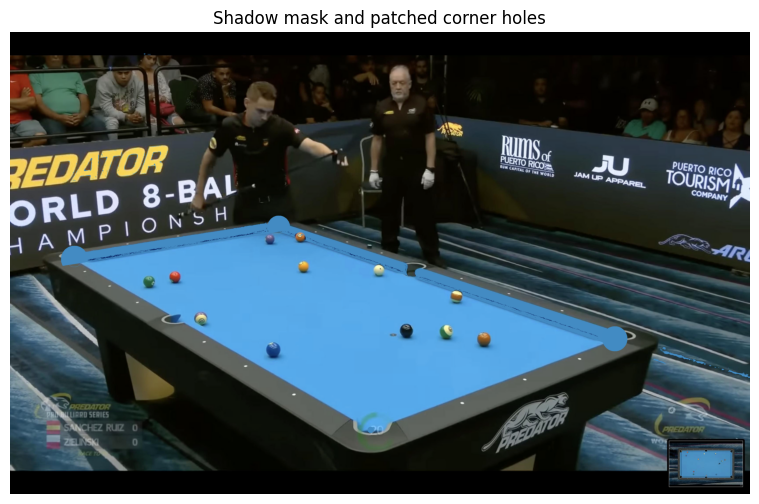

In [15]:
circle_hsv_color = (h_med, s_med, v_med) 

tl = (int(tl_hole[0]), int(tl_hole[1]))
tr = (int(tr_hole[0]), int(tr_hole[1]))
br = (int(br_hole[0]), int(br_hole[1]))
bl = (int(bl_hole[0]), int(bl_hole[1]))

cv2.circle(hsv_image_shadow_masked, tl, int(distance_tl/2), circle_hsv_color, 1) #just line for top
cv2.circle(hsv_image_shadow_masked, tr, int(distance_tr/2), circle_hsv_color, 1)
cv2.circle(hsv_image_shadow_masked, br, int(distance_br/2)+10, circle_hsv_color, -1) #fill for bottom
cv2.circle(hsv_image_shadow_masked, bl, int(distance_bl/2)+10, circle_hsv_color, -1)

# Line Mask 
A, B, C = top_line_inner_full
y_line = -(A * coords[:, 0] + C) / B
mask_line_flat = coords[:, 1] < y_line 

# Circle Masks
# Calculate circle radius based on distances between inner and outer points, with some padding
radius_tl = int(distance_tl/2) +25
radius_tr = int(distance_tr/2) + 30

# Create boolean masks for points inside the top-left and top-right circles
mask_circle_tl_flat = (coords[:, 0] - tl[0])**2 + (coords[:, 1] - tl[1])**2 <= radius_tl**2
mask_circle_tr_flat = (coords[:, 0] - tr[0])**2 + (coords[:, 1] - tr[1])**2 <= radius_tr**2

mask_top_circles_flat = mask_circle_tl_flat | mask_circle_tr_flat

# Combine Line and Circle Conditions
# The point must be above the line and inside one of the top circles
final_mask_flat = mask_line_flat & mask_top_circles_flat
final_mask = final_mask_flat.reshape(height, width)

hsv_image_shadow_masked[final_mask] = [h_med, s_med, v_med]


#patch holes in top view

if is_top:
    cv2.circle(hsv_image_shadow_masked, (int(tl_outer[0]), int(tl_outer[1])), int(distance_tl/2)+50, circle_hsv_color, -1)
    cv2.circle(hsv_image_shadow_masked, (int(tr_outer[0]), int(tr_outer[1])), int(distance_tr/2)+50, circle_hsv_color, -1)
    cv2.circle(hsv_image_shadow_masked, (int(br_outer[0]), int(br_outer[1])), int(distance_br/2)+50, circle_hsv_color, -1)
    cv2.circle(hsv_image_shadow_masked, (int(bl_outer[0]), int(bl_outer[1])), int(distance_bl/2)+50, circle_hsv_color, -1)
    mid_point_upper = ((tl_outer + tr_outer) / 2).astype(int)
    mid_point_lower = ((bl_outer + br_outer) / 2).astype(int)
    cv2.circle(hsv_image_shadow_masked, (mid_point_upper[0], mid_point_upper[1]), int(distance_tl/2)+50, circle_hsv_color, -1)
    cv2.circle(hsv_image_shadow_masked, (mid_point_lower[0], mid_point_lower[1]), int(distance_tl/2)+50, circle_hsv_color, -1)

display_image = cv2.cvtColor(hsv_image_shadow_masked, cv2.COLOR_HSV2RGB)    
plt.figure(figsize=(10, 6))
plt.imshow(display_image)
plt.title('Shadow mask and patched corner holes')
plt.axis('off')
plt.show()

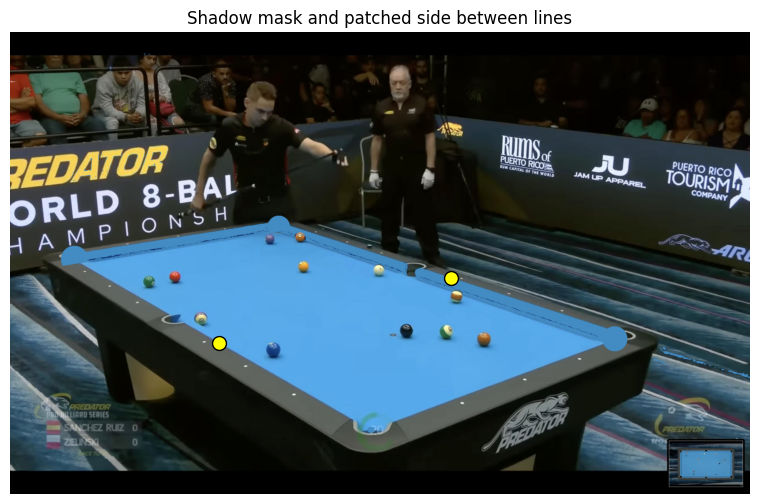

In [16]:

mid_l = (tl_outer + bl_outer) / 2
mid_r = (tr_outer + br_outer) / 2

if is_front:
    A_out, B_out, C_out = side_line_r_outer_full
    A_in, B_in, C_in = side_line_r_inner_full

    y_line_r_outer = -(A_out * coords[:, 0] + C_out) / B_out
    y_line_r_inner = -(A_in * coords[:, 0] + C_in) / B_in
    
    A_out_l, B_out_l, C_out_l = side_line_l_outer_full
    A_in_l, B_in_l, C_in_l = side_line_l_inner_full

    y_line_l_outer = -(A_out_l * coords[:, 0] + C_out_l) / B_out_l
    y_line_l_inner = -(A_in_l * coords[:, 0] + C_in_l) / B_in_l

    mask_above_inner_flat_l = coords[:, 1] < y_line_l_inner
    mask_below_outer_flat_l = coords[:, 1] > y_line_l_outer

    mask_above_inner_flat = coords[:, 1] < y_line_r_inner
    mask_below_outer_flat = coords[:, 1] > y_line_r_outer
    
    mask_side_combined_flat = (mask_above_inner_flat & mask_below_outer_flat) | (mask_above_inner_flat_l & mask_below_outer_flat_l) 
    final_side_mask = mask_side_combined_flat.reshape(height, width)

    hsv_image_shadow_masked[final_side_mask] = [h_med, s_med, v_med]


display_image = cv2.cvtColor(hsv_image_shadow_masked, cv2.COLOR_HSV2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(display_image)
plt.scatter(mid_l[0], mid_l[1], color='yellow', s=100, edgecolors='black', zorder=5)
plt.scatter(mid_r[0], mid_r[1], color='yellow', s=100, edgecolors='black', zorder=5)
plt.title('Shadow mask and patched side between lines')
plt.axis('off')
plt.show()

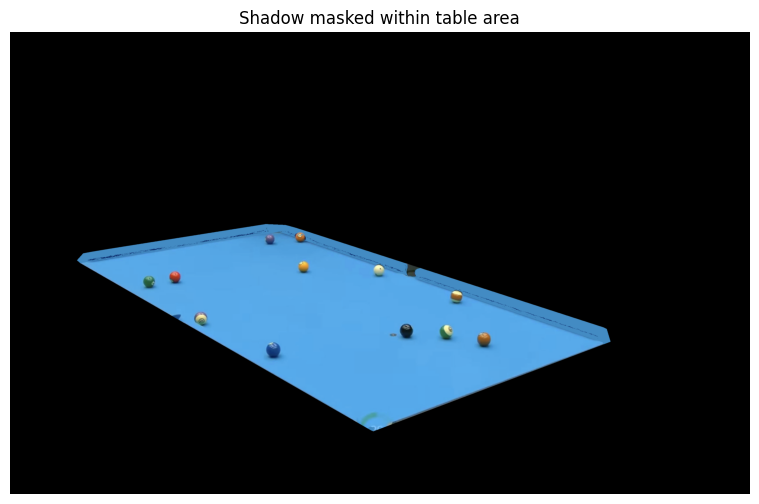

In [17]:

mask_hull = np.zeros(hsv_image_shadow_masked.shape, dtype=np.uint8)
cv2.fillPoly(mask_hull, [hull], (255, 255, 255))
masked_image = cv2.bitwise_and(hsv_image_shadow_masked, mask_hull)
display_image = cv2.cvtColor(masked_image, cv2.COLOR_HSV2RGB)


plt.figure(figsize=(10, 6))
plt.imshow(display_image)
plt.title('Shadow masked within table area')
plt.axis('off')
plt.show()



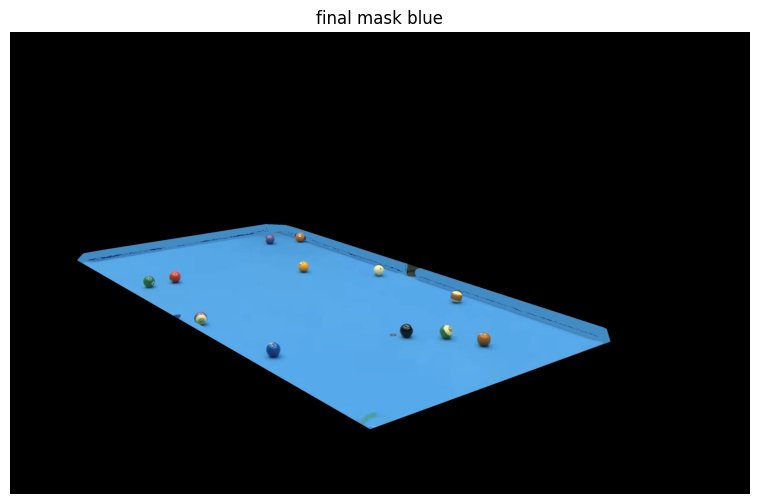

In [18]:

mask_hull = np.zeros(hsv_image_shadow_masked.shape, dtype=np.uint8)
cv2.fillPoly(mask_hull, [hull], (255, 255, 255))

"""if is_angle and tl_outer[0] < bl_outer[0]:
    # Get the grid of coordinates for the image
    height, width = hsv_image_shadow_masked.shape[:2]
    xx, yy = np.meshgrid(np.arange(width), np.arange(height))

    # Unpack your angled left inner line
    A, B, C = side_line_l_inner_full

    # Calculate the exact Y-value of the line for every X coordinate
    y_line = -(A * xx + C) / B

    # Create a mask for points "below" the line (larger Y values)
    mask_below_line = yy > y_line

    # Force those specific pixels to black (0, 0, 0) on the hull mask
    mask_hull[mask_below_line] = (0, 0, 0)
# ---------------------------------------------------------"""

if is_angle and tl_outer[0] < bl_outer[0]:
    height, width = hsv_image_shadow_masked.shape[:2]
    xx, yy = np.meshgrid(np.arange(width), np.arange(height))

    A_left, B_left, C_left = side_line_l_inner_full
    y_line_left = -(A_left * xx + C_left) / B_left
    mask_below_left = yy > y_line_left

    A_bot, B_bot, C_bot = bot_line_inner_full
    y_line_bot = -(A_bot * xx + C_bot) / B_bot
    mask_below_bot = yy > y_line_bot

    mask_to_cut = mask_below_left | mask_below_bot

    mask_hull[mask_to_cut] = 0

masked_image = cv2.bitwise_and(hsv_image_shadow_masked, mask_hull)
display_image = cv2.cvtColor(masked_image, cv2.COLOR_HSV2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(display_image)
plt.title('final mask blue')
plt.axis('off')
plt.show()

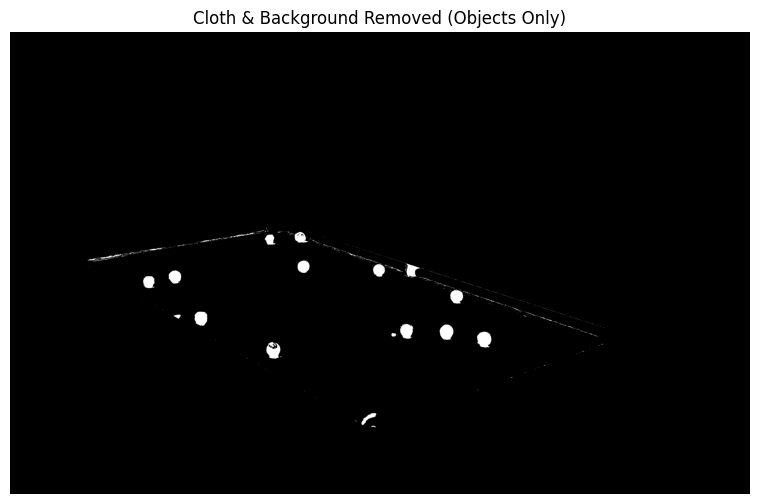

In [19]:


h_tol = 6
s_tol_up = 10
s_tol_down = 40
v_tol_up = 50
v_tol_down = 80

lower_blue = np.array([h_med - h_tol, s_med - s_tol_down, v_med - v_tol_down])
upper_blue = np.array([h_med + h_tol, s_med + s_tol_up, v_med + v_tol_up])

lower_blue = np.clip(lower_blue, [0, 0, 0], [179, 255, 255])
upper_blue = np.clip(upper_blue, [0, 0, 0], [179, 255, 255])

# 1. Find the blue cloth
mask_cloth = cv2.inRange(masked_image, lower_blue, upper_blue)

# 2. NEW: Find pixels that actually have color/light (Value > 0)
# This perfectly isolates your objects while ignoring pitch-black [0,0,0] pixels
lower_any_color = np.array([0, 0, 1])
upper_any_color = np.array([179, 255, 255])
mask_not_black = cv2.inRange(masked_image, lower_any_color, upper_any_color)

# 3. Create the object mask: It must NOT be cloth, AND it must NOT be already black
mask_inverted_cloth = cv2.bitwise_not(mask_cloth)
mask = cv2.bitwise_and(mask_inverted_cloth, mask_not_black)

# 4. Restrict to the table hull bounds
mask_hull = np.zeros(masked_image.shape[:2], dtype=np.uint8)
cv2.fillPoly(mask_hull, [hull], 255)

mask = cv2.bitwise_and(mask, mask_hull)

# Show the fixed mask
plt.figure(figsize=(12, 6))
plt.imshow(mask, cmap='gray')
plt.title('Cloth & Background Removed (Objects Only)')
plt.axis('off')
plt.show()

-------------------------------

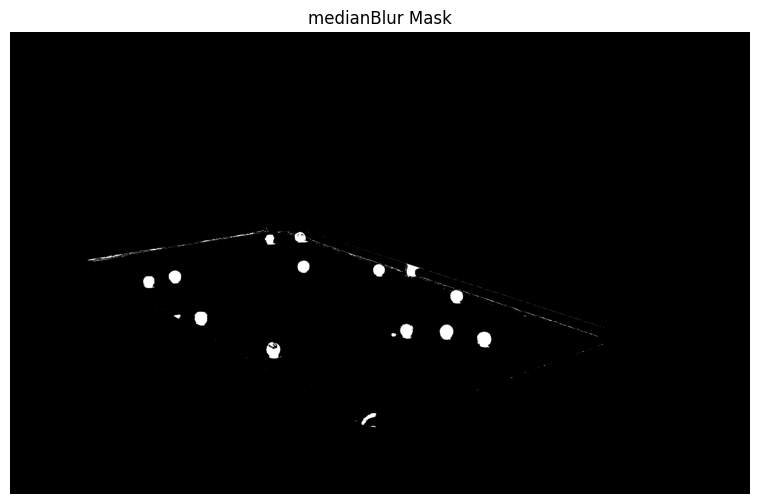

In [20]:

gray_mask = cv2.medianBlur(mask, 9)

#gray_mask = cv2.GaussianBlur(mask, (5, 5), 2)
plt.figure(figsize=(12, 6))
plt.imshow(mask, cmap='gray')
plt.title('medianBlur Mask')
plt.axis('off')
plt.show()

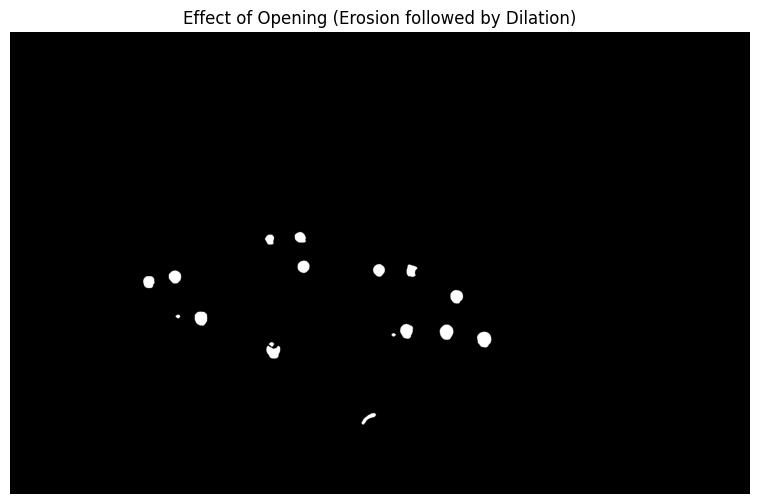

In [21]:

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))

eroded_mask = cv2.dilate(gray_mask, kernel, iterations=6)
eroded_mask = cv2.erode(eroded_mask, kernel, iterations=6)

eroded_mask = cv2.erode(gray_mask, kernel, iterations=6)
opened_mask = cv2.dilate(eroded_mask, kernel, iterations=6)

plt.figure(figsize=(12, 6))
plt.imshow(opened_mask, cmap='gray')
plt.title('Effect of Opening (Erosion followed by Dilation)')
plt.axis('off')
plt.show()

Found 13 circle(s)
  Ball at (1982,1362) r=31
  Ball at (748,1114) r=29
  Ball at (2028,1202) r=29
  Ball at (2152,1396) r=34
  Ball at (1334,1065) r=26
  Ball at (867,1298) r=30
  Ball at (629,1135) r=26
  Ball at (1315,932) r=24
  Ball at (1674,1082) r=25
  Ball at (1802,1357) r=32
  Ball at (1828,1088) r=28
  Ball at (1200,1446) r=38
  Ball at (1180,942) r=21


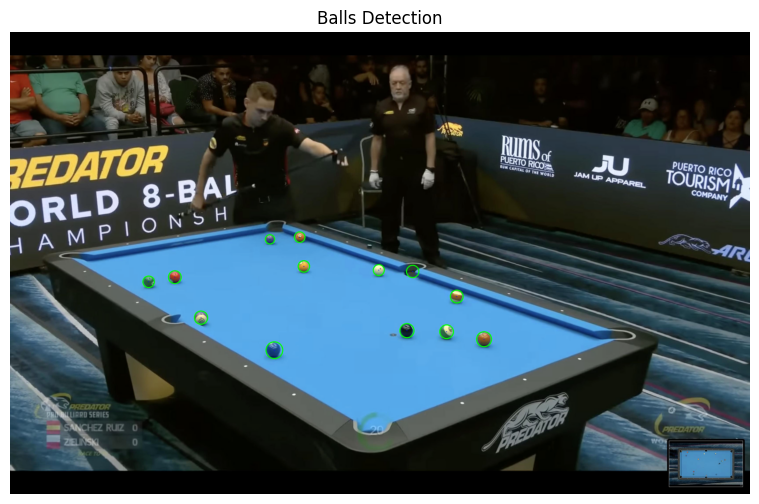

In [22]:
#Can't find parameters that work for all images (maybe try different values for top view, angle and side view)

circles = cv2.HoughCircles(
    opened_mask,          
    cv2.HOUGH_GRADIENT,
    dp=1.4,
    minDist=22,
    param1=40,
    param2=18,
    minRadius=19,
    maxRadius=52
)

result = cv2.cvtColor(hsv_image, cv2.COLOR_HSV2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    print(f"Found {len(circles)} circle(s)")
    for (cx, cy, r) in circles:
        if r < 12:
            print(f"  Skipped small blob at ({cx},{cy}) r={r}")
            continue
        cv2.circle(result, (cx, cy), r, (0, 255, 0), 4)
        cv2.circle(result, (cx, cy), 2, (0, 0, 255), -1)
        print(f"  Ball at ({cx},{cy}) r={r}")
else:
    print("No circles found")


plt.figure(figsize=(12, 6))
plt.imshow(result)
plt.title('Balls Detection')
plt.axis('off')
plt.show()

----------------- Down this line is shit I tried before and some experiments------------

In [23]:
h, w = final_crop.shape[:2]
cy, cx = h // 2, w // 2
margin_y, margin_x = int(h * 0.4), int(w * 0.4)  # 20% each side = 40% total

center_region = final_crop[cy-margin_y:cy+margin_y, cx-margin_x:cx+margin_x]

# Get dominant color in HSV
center_hsv = cv2.cvtColor(center_region, cv2.COLOR_RGB2HSV)
mean_h = np.mean(center_hsv[:,:,0])
mean_s = np.mean(center_hsv[:,:,1])
mean_v = np.mean(center_hsv[:,:,2])
print(f"Dominant HSV: H={mean_h:.1f}, S={mean_s:.1f}, V={mean_v:.1f}")

# Build range around sampled values
# --- TWEAK THESE VALUES ---
h_low, h_high = 3, 5      # Strict Hue (The actual color)
s_low, s_high = 40, 40    # Saturation
v_low, v_high = 20, 50    # Brightness (Increase v_low to catch more shadows)

# Build the ranges using the specific variables
lower = np.array([mean_h - h_low,  mean_s - s_low,  mean_v - v_low]).clip(0, 255)
upper = np.array([mean_h + h_high, mean_s + s_high, mean_v + v_high]).clip(0, 255)


hsv_crop = cv2.cvtColor(final_crop, cv2.COLOR_RGB2HSV)
felt_mask_crop = cv2.inRange(hsv_crop, lower, upper)

# Apply pink
pink_crop = final_crop.copy()
pink_crop[felt_mask_crop == 255] = [255, 182, 193]

plt.figure(figsize=(10, 6))
plt.imshow(pink_crop)
plt.title('Felt Replaced')
plt.axis('off')
plt.show()

NameError: name 'final_crop' is not defined

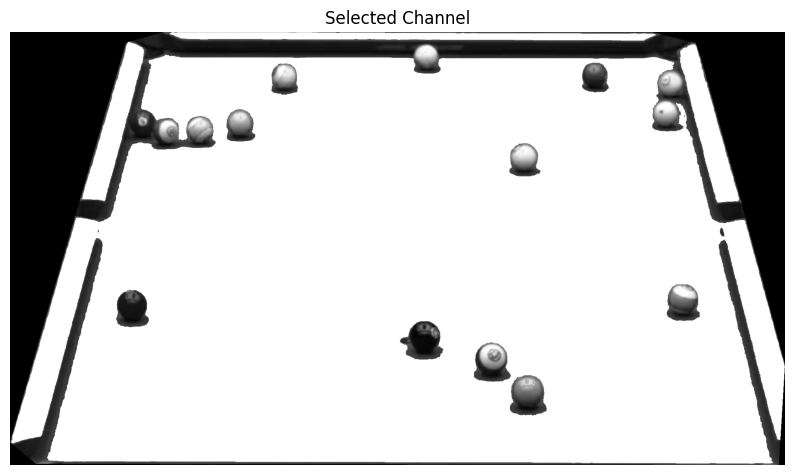

In [ ]:

pink_crop_c1 =pink_crop[:, :, 0]
plt.figure(figsize=(10, 6))
plt.imshow(pink_crop_c1, cmap='gray')
plt.title('Selected Channel')
plt.axis('off')
plt.show()

Balls detected: 27


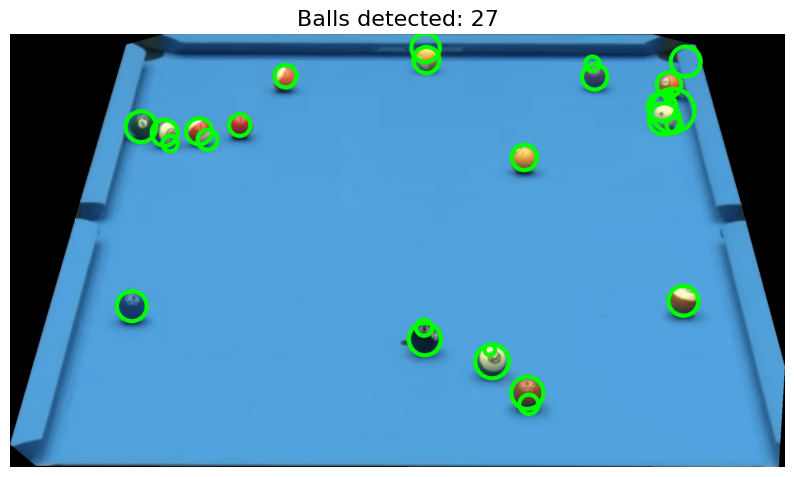

In [ ]:
circles = cv2.HoughCircles(
    pink_crop_c1,        # input grayscale image
    cv2.HOUGH_GRADIENT, # detection method (only available option)
    dp=1,               # accumulator resolution matches image resolution
    minDist=30,         # minimum pixel distance between circle centers
    param1=60,          # canny edge upper threshold (lower = more edges)
    param2=20,          # accumulator threshold (lower = more circles detected)
    minRadius=9,       # minimum ball radius in pixels
    maxRadius=60        # maximum ball radius in pixels
)

vis=final_crop.copy()
#vis = cv2.cvtColor(result_interior, cv2.COLOR_GRAY2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for (x, y, r) in circles:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 10)
    
    detection_count = len(circles)
    print(f"Balls detected: {detection_count}")
else:    
    detection_count = 0
    print("No balls detected.")

# 3. Display the result
plt.figure(figsize=(10, 6))
plt.title(f'Balls detected: {detection_count}', fontsize=16)
# Ensure we don't use cmap='gray' here so the green shows up
plt.imshow(vis,  cmap='grey') 
plt.axis('off')
plt.show()

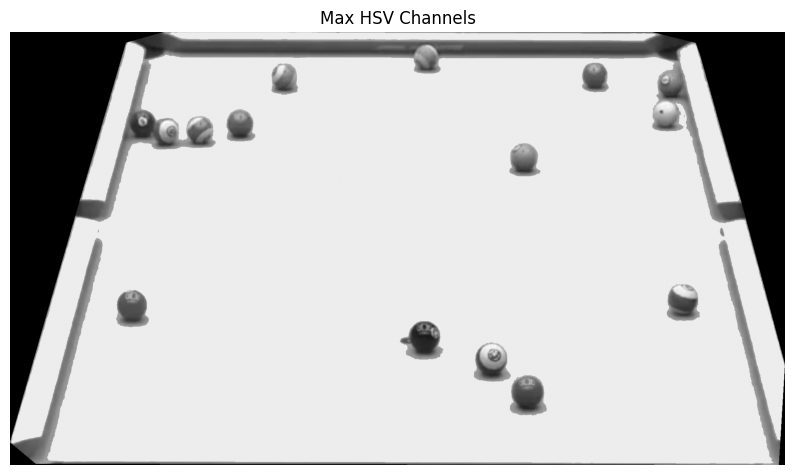

Balls detected: 26


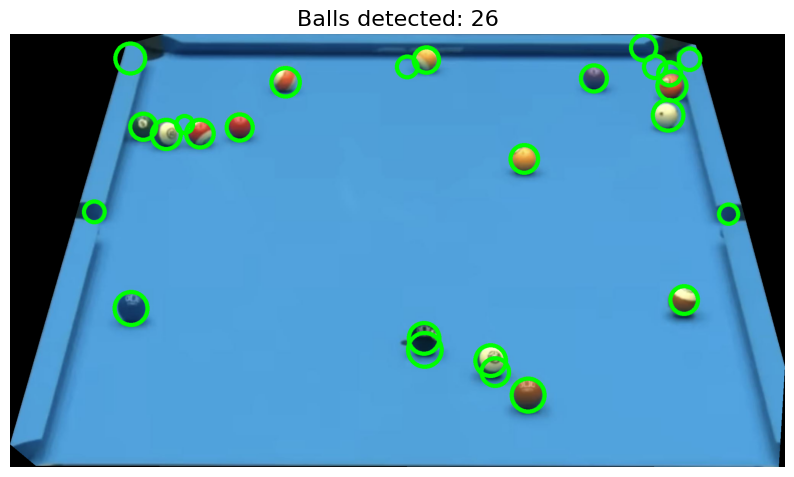

In [ ]:
#combined = np.maximum(pink_crop[:,:,0], pink_crop[:,:,2]) #some balls on visible on hue, saturation, value channels take the max of each

combined=   (0.4*pink_crop[:,:,0] + 0.7 * pink_crop[:,:,2]).clip(0, 255).astype(np.uint8) #try to do weighted sums of the 3 channels

plt.figure(figsize=(10, 6))
plt.imshow(combined, cmap='gray')
plt.title('Max HSV Channels')
plt.axis('off')
plt.show()

circles = cv2.HoughCircles(
    combined,        # input grayscale image
    cv2.HOUGH_GRADIENT, # detection method (only available option)
    dp=1,               # accumulator resolution matches image resolution
    minDist=30,         # minimum pixel distance between circle centers
    param1=60,          # canny edge upper threshold (lower = more edges)
    param2=15,          # accumulator threshold (lower = more circles detected)
    minRadius=20,       # minimum ball radius in pixels
    maxRadius=45        # maximum ball radius in pixels
)

vis=final_crop.copy()
#vis = cv2.cvtColor(result_interior, cv2.COLOR_GRAY2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for (x, y, r) in circles:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 10)
    
    detection_count = len(circles)
    print(f"Balls detected: {detection_count}")
else:    
    detection_count = 0
    print("No balls detected.")

# 3. Display the result
plt.figure(figsize=(10, 6))
plt.title(f'Balls detected: {detection_count}', fontsize=16)
# Ensure we don't use cmap='gray' here so the green shows up
plt.imshow(vis,  cmap='grey') 
plt.axis('off')
plt.show()

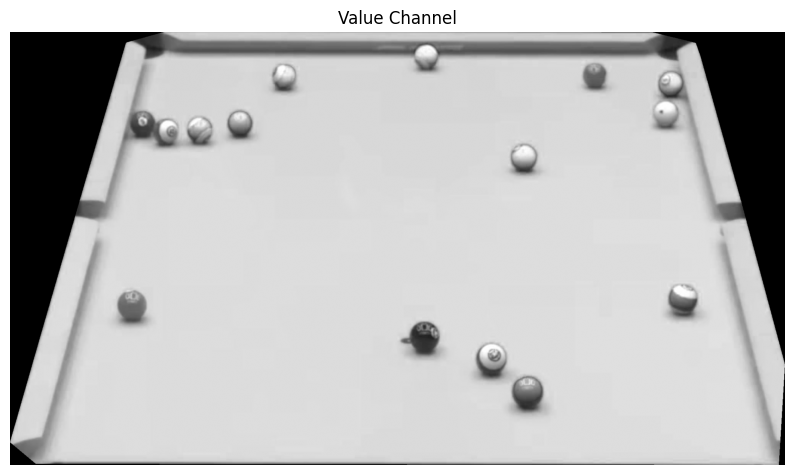

In [ ]:
hsv_crop = cv2.cvtColor(final_crop, cv2.COLOR_RGB2HSV)
hsv_crop_c3 =hsv_crop[:, :, 2]
plt.figure(figsize=(10, 6))
plt.imshow(hsv_crop_c3, cmap='gray')
plt.title('Value Channel')
plt.axis('off')
plt.show()

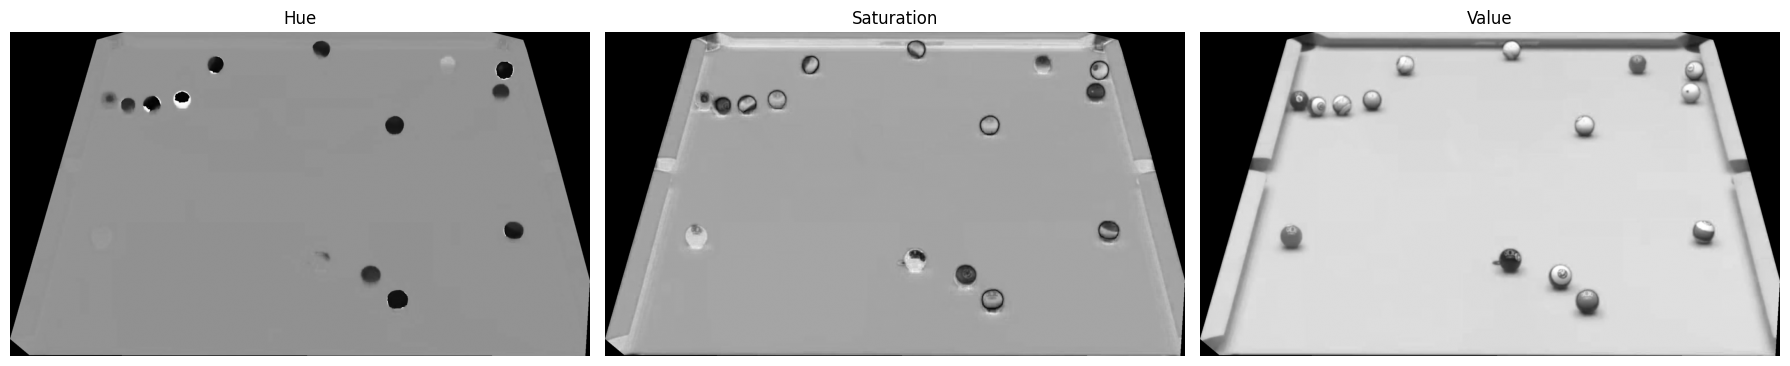

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (ax, title) in enumerate(zip(axes, ['Hue', 'Saturation', 'Value'])):
    ax.imshow(hsv_crop[:,:,i], cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

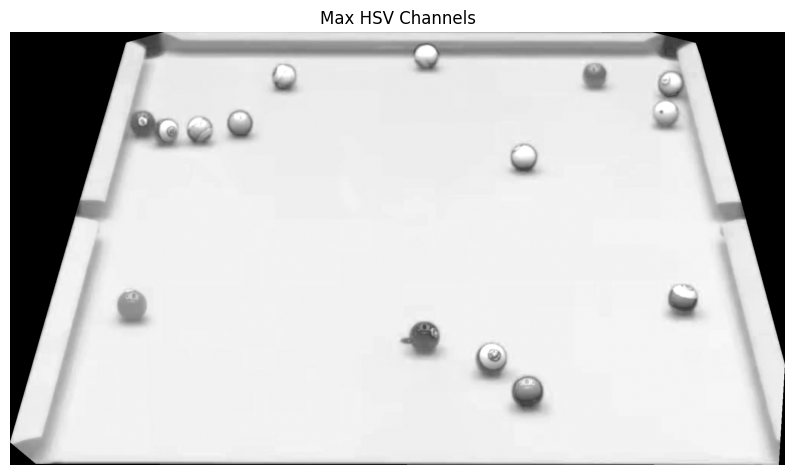

In [ ]:
combined = np.maximum(hsv_crop[:,:,0], hsv_crop[:,:,1]) #some balls on visible on hue, saturation, value channels take the max of each
combined = np.maximum(combined, hsv_crop[:,:,2])

combined=   (0.3*combined + 0.8 * hsv_crop[:,:,2]).clip(0, 255).astype(np.uint8) #try to do weighted sums of the 3 channels

plt.figure(figsize=(10, 6))
plt.imshow(combined, cmap='gray')
plt.title('Max HSV Channels')
plt.axis('off')
plt.show()

Balls detected: 27


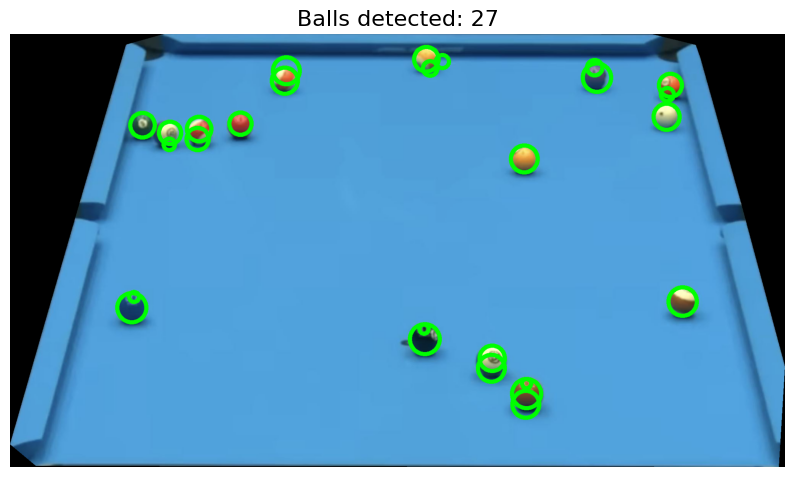

In [ ]:
circles = cv2.HoughCircles(
    hsv_crop[:,:,2],        # input grayscale image
    cv2.HOUGH_GRADIENT, # detection method (only available option)
    dp=1,               # accumulator resolution matches image resolution
    minDist=25,         # minimum pixel distance between circle centers
    param1=60,          # canny edge upper threshold (lower = more edges)
    param2=19,          # accumulator threshold (lower = more circles detected)
    minRadius=10,       # minimum ball radius in pixels
    maxRadius=40        # maximum ball radius in pixels
)

vis=hsv_image_shadow_maskedcopy()
#vis = cv2.cvtColor(result_interior, cv2.COLOR_GRAY2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for (x, y, r) in circles:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 10)
    
    detection_count = len(circles)
    print(f"Balls detected: {detection_count}")
else:    
    detection_count = 0
    print("No balls detected.")

# 3. Display the result
plt.figure(figsize=(10, 6))
plt.title(f'Balls detected: {detection_count}', fontsize=16)
# Ensure we don't use cmap='gray' here so the green shows up
plt.imshow(vis,  cmap='grey') 
plt.axis('off')
plt.show()